# Two-Tunable Qubit Hamiltonian

Model and plumbing live in `two_qubit_model.py`; this notebook sets parameters, builds control pulses and rolls out the dynamics.

**Frame:** rotating at each qubit's idle frequency, RWA.

$$\frac{H(t)}{2\pi} = \sum_i \Big[\Delta_i(t)\, n_i + \tfrac{\alpha_i}{2} b_i^{\dagger 2} b_i^2 + \tfrac{u_{x,i}}{2}(b_i + b_i^\dagger) + \tfrac{u_{y,i}}{2}\, i(b_i^\dagger - b_i)\Big] + J\big(e^{i\delta t} b_1^\dagger b_2 + \text{h.c.}\big)$$

* $\Delta_i(t) = f_i(I(t)) - f_{\text{idle},i}$, with $f_i(\Phi) = f_{\max,i}\sqrt{|\cos(\pi\Phi_i/\Phi_0)|}$ and $\Phi_i = \sum_j M_{ij} I_j$ (crosstalk included).
* $\delta = 2\pi(f_{\text{idle},1} - f_{\text{idle},2})$: the coupling only acts efficiently when flux brings the qubits into resonance.
* `n_levels=2` gives the Pauli model; `n_levels=3` adds leakage.

**Units:** ns, GHz (cyclic), mA, pH. **Controls** are piecewise constant on `N` slices of width `dt`: `I`, `ux`, `uy` each have shape `(2, N)`.

In [1]:
import numpy as np
import qutip as qt
import matplotlib.pyplot as plt

from two_qubit_model import QubitParams, SystemParams, Controls, TwoQubitModel

## System parameters

In [2]:
params = SystemParams(
    q1=QubitParams(f_max=6.0, alpha=-0.20),   # GHz
    q2=QubitParams(f_max=5.6, alpha=-0.21),
    J=0.010,                                  # GHz (10 MHz)
    M=[[2.00, 0.05],                          # pH, M[i, j]: flux line j -> SQUID i
       [0.05, 2.00]],
    I_idle=[0.0, 0.0],                        # mA (both parked at the sweet spot)
    n_levels=3,
)
model = TwoQubitModel(params)
print("idle frequencies [GHz]:", model.f_idle)
print("idle detuning delta/2pi [GHz]:", model.delta / (2 * np.pi))

idle frequencies [GHz]: [6.  5.6]
idle detuning delta/2pi [GHz]: 0.40000000000000036


## Example control pulses
A Gaussian X π pulse on qubit 1 (|00⟩ → |10⟩), then a flux pulse that tunes qubit 1 into resonance with qubit 2 with a Gaussian-square envelope (5 ns Gaussian edges, flat top $1/(4J)$) (|10⟩ → |01⟩).
Replace these arrays with your optimizer's output.

2438
resonance currents [mA]: [ 0.16904759 -0.00422619] | total duration 48.8 ns


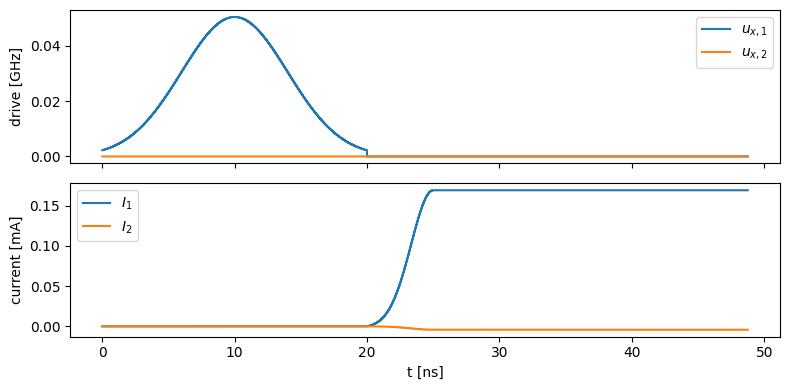

In [3]:
dt = 0.02     
t_edge = 5.0                               # ns, Gaussian rise / fall of the flux pulse                             # ns per slice
t_pi, t_swap = 20.0, 1 / (4 * params.J) - t_edge / 4.0    # ns
N_pi, N_swap, N_edge = round(t_pi / dt), round(t_swap / dt), round(t_edge / dt)
N = N_pi + N_edge + N_swap      # pi pulse | rise | flat top | fall
print(N)
ctrl = Controls.idle(model, N, dt)          # flux at idle, drives off

# Gaussian pi pulse on qubit 1, normalized so the area gives exactly a pi rotation
t = ctrl.t_mid[:N_pi]
g = np.exp(-0.5 * ((t - t_pi / 2) / (t_pi / 5)) ** 2)
ctrl.ux[0, :N_pi] = 0.5 * g / (g.sum() * dt)

# Flux pulse: Gaussian-square from idle to the currents that put qubit 1 at qubit 2's
# idle frequency (crosstalk-corrected). Edges are half-Gaussians with sigma = t_edge/3,
# offset so they start/end exactly at idle; the flat top lasts t_swap.
I_res = model.currents_for_frequencies([model.f_idle[1], model.f_idle[1]])
sigma = t_edge / 3
t_on, t_off = t_pi + t_edge, t_pi + t_edge + t_swap          # flat-top start / end
tm = ctrl.t_mid
g0 = np.exp(-0.5 * (t_edge / sigma) ** 2)                     # Gaussian value at the edge start
edge = lambda x: np.clip((np.exp(-0.5 * (x / sigma) ** 2) - g0) / (1 - g0), 0, 1)
env = np.where(tm < t_pi, 0.0,
      np.where(tm < t_on, edge(tm - t_on),
      np.where(tm <= t_off, 1.0, edge(tm - t_off))))
ctrl.I[:] = model.p.I_idle[:, None] + env[None, :] * (I_res - model.p.I_idle)[:, None]
print("resonance currents [mA]:", I_res, f"| total duration {ctrl.duration:.1f} ns")

fig, ax = plt.subplots(2, 1, sharex=True, figsize=(8, 4))
for i in range(2):
    ax[0].step(ctrl.t_mid, ctrl.ux[i], where="mid", label=f"$u_{{x,{i+1}}}$")
    ax[1].step(ctrl.t_mid, ctrl.I[i], where="mid", label=f"$I_{i+1}$")
ax[0].set_ylabel("drive [GHz]"); ax[1].set_ylabel("current [mA]"); ax[1].set_xlabel("t [ns]")
ax[0].legend(); ax[1].legend(); plt.tight_layout()

## Rollout

{'00': 0.01273, '01': 0.98476, '10': 0.00246, '11': 0.0, 'leak': 5e-05}


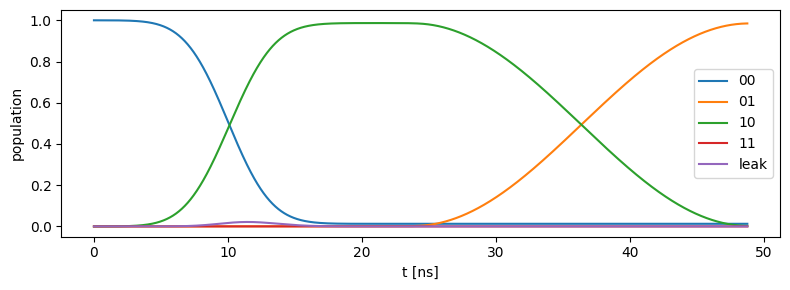

In [4]:
labels = ["00", "01", "10", "11", "leak"]
P = [model.basis(0, 0).proj(), model.basis(0, 1).proj(), model.basis(1, 0).proj(), model.basis(1, 1).proj()]
P.append(qt.qeye(model.dims) - sum(P))

# Closed system. Pass c_ops=model.collapse_ops(T1=(30e3, 30e3), Tphi=(40e3, 40e3)) for decoherence.
res = model.evolve(ctrl, model.basis(0, 0), e_ops=P)

plt.figure(figsize=(8, 3))
for lab, p in zip(labels, res.expect):
    plt.plot(res.times, p, label=lab)
plt.xlabel("t [ns]"); plt.ylabel("population"); plt.legend(); plt.tight_layout()
print({lab: round(float(p[-1]), 5) for lab, p in zip(labels, res.expect)})

# Online "Hardware" Model
Our mutual inductance is SHITTT

{'00': 0.01273, '01': 0.05433, '10': 0.93289, '11': 0.0, 'leak': 5e-05}


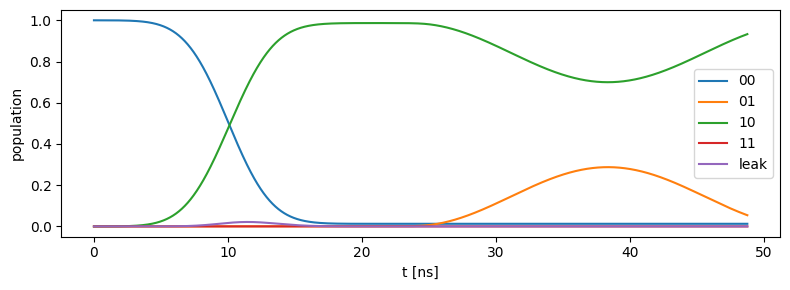

In [5]:
real_params = SystemParams(
    q1=QubitParams(f_max=6.0, alpha=-0.20),   # GHz
    q2=QubitParams(f_max=5.6, alpha=-0.21),
    J=0.010,                                  # GHz (10 MHz)
    M=[[2.00, 0.55],                          # pH, M[i, j]: flux line j -> SQUID i
       [0.55, 2.00]],                         # This is SHITTTTT
    I_idle=[0.0, 0.0],                        # mA (both parked at the sweet spot)
    n_levels=3,
)
real_model = TwoQubitModel(real_params)

labels = ["00", "01", "10", "11", "leak"]
P = [real_model.basis(0, 0).proj(), real_model.basis(0, 1).proj(), real_model.basis(1, 0).proj(), real_model.basis(1, 1).proj()]
P.append(qt.qeye(real_model.dims) - sum(P))


# Closed system. Pass c_ops=real_model.collapse_ops(T1=(30e3, 30e3), Tphi=(40e3, 40e3)) for decoherence.
real_res = real_model.evolve(ctrl, real_model.basis(0, 0), e_ops=P)

plt.figure(figsize=(8, 3))
for lab, p in zip(labels, real_res.expect):
    plt.plot(real_res.times, p, label=lab)
plt.xlabel("t [ns]"); plt.ylabel("population"); plt.legend(); plt.tight_layout()
print({lab: round(float(p[-1]), 5) for lab, p in zip(labels, real_res.expect)})

## SVD-ILC
Nominal pulse `ctrl` in the offline `model` (crosstalk 0.05); "hardware" = `real_model` (crosstalk 0.55) with shot noise.

1. Analytic Jacobian $J = \partial y(t_k)/\partial a_m(t_n)$ of the offline model, stacked over checkpoint times, input states and Pauli observables.
2. Rank-4 SVD $J \approx U_r \Sigma_r V_r^\top$: $V_r$ = pulse-correction modes, $U_r$ = error modes.
3. Pick 4 measurement times from $U_r$ (greedy D-optimal / max Fisher information).
4. ILC: measure hardware at those 4 times only, fit the 4 mode coefficients, $a \leftarrow a - g\,V_r c$.

J: (1176, 14628)  Sigma_r: [28.521 11.993  5.064  3.397  2.978  2.59 ]
measurement times [ns]: [29.5  34.   39.   48.76]
(1176,)


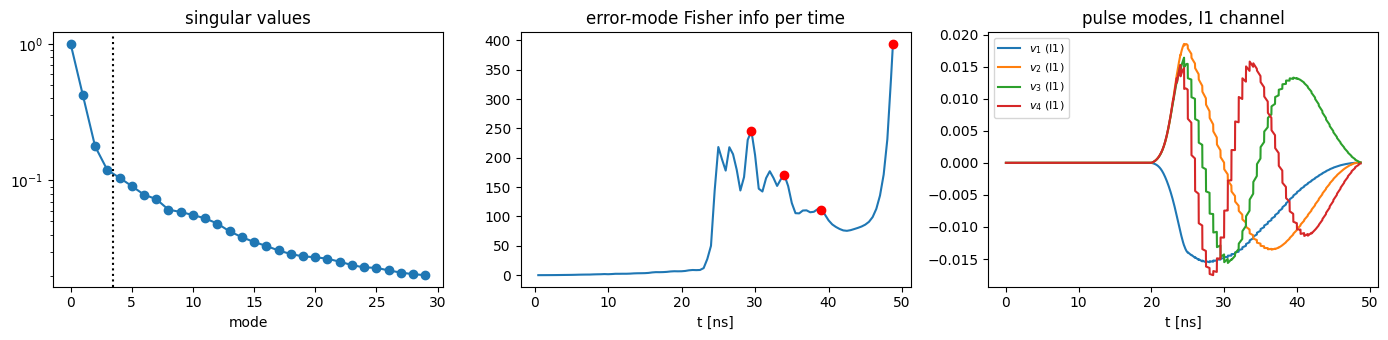

In [6]:
from ilc import SVDILC, CHANNELS, embedded_paulis, product_state, tracking_fidelity

USE_DRIVES = True                                                 # False: ILC corrects flux (I1, I2) only
ACTIVE = CHANNELS if USE_DRIVES else ["I1", "I2"]

SVD_RANK = 6

paulis = embedded_paulis(model)                                   # XI, IX, YI, IY, ZI, IZ
states = [product_state(model, "0", "0"), product_state(model, "+", "+")]
checkpoints = np.unique(np.append(np.arange(25, ctrl.n_slices + 1, 25), ctrl.n_slices))  # every 0.5 ns + final time
ALWAYS_MEASURE_FINAL = True                                       # final time is measured on every ILC step
REQUIRED = [len(checkpoints) - 1] if ALWAYS_MEASURE_FINAL else None

ilc = SVDILC(model, states, list(paulis.values()), checkpoints, active_channels=ACTIVE)
J, y_nom = ilc.compute_jacobian(ctrl)
V_r, U_r, Sigma_r = ilc.compute_svd_basis(J, r_rank=SVD_RANK)


SHOTS = 1000
meas_pos, score = ilc.select_measurement_times(U_r, n_times=4, y_nom=y_nom, shots=SHOTS, required=REQUIRED)
meas_rows = ilc.rows_for_times(meas_pos)
t_ck = checkpoints * ctrl.dt
print("J:", J.shape, " Sigma_r:", np.round(Sigma_r, 3))
print("measurement times [ns]:", t_ck[meas_pos])

fig, ax = plt.subplots(1, 3, figsize=(14, 3.5))
S_all = np.linalg.svd(J, compute_uv=False)
print(S_all.shape)
ax[0].semilogy(S_all[:30] / S_all[0], "o-"); ax[0].axvline(3.5, color="k", ls=":")
ax[0].set_title("singular values"); ax[0].set_xlabel("mode")
ax[1].plot(t_ck, score); ax[1].plot(t_ck[meas_pos], score[meas_pos], "ro")
ax[1].set_title("error-mode Fisher info per time"); ax[1].set_xlabel("t [ns]")
modes = V_r.T.reshape(SVD_RANK, 6, -1) * ilc.scales[None, :, None]
for i in range(4):
    ax[2].plot(ctrl.t_mid, modes[i, 0], label=f"$v_{i+1}$ (I1)")
ax[2].set_title("pulse modes, I1 channel"); ax[2].set_xlabel("t [ns]"); ax[2].legend(fontsize=8)
plt.tight_layout()

iter 0: rms trajectory error 0.3786   tracking fidelity 0.03675
iter 1: rms trajectory error 0.3189   tracking fidelity 0.05647
iter 2: rms trajectory error 0.3044   tracking fidelity 0.03395
iter 3: rms trajectory error 0.2929   tracking fidelity 0.02740
iter 4: rms trajectory error 0.2881   tracking fidelity 0.01969
iter 5: rms trajectory error 0.2800   tracking fidelity 0.02040
iter 6: rms trajectory error 0.2746   tracking fidelity 0.02122
iter 7: rms trajectory error 0.2725   tracking fidelity 0.01979
iter 8: rms trajectory error 0.2712   tracking fidelity 0.01745
iter 9: rms trajectory error 0.2654   tracking fidelity 0.01645
iter 10: rms trajectory error 0.2640   tracking fidelity 0.01421
iter 11: rms trajectory error 0.2640   tracking fidelity 0.01495
iter 12: rms trajectory error 0.2656   tracking fidelity 0.01547
iter 13: rms trajectory error 0.2661   tracking fidelity 0.01631
iter 14: rms trajectory error 0.2661   tracking fidelity 0.01577
iter 15: rms trajectory error 0.263

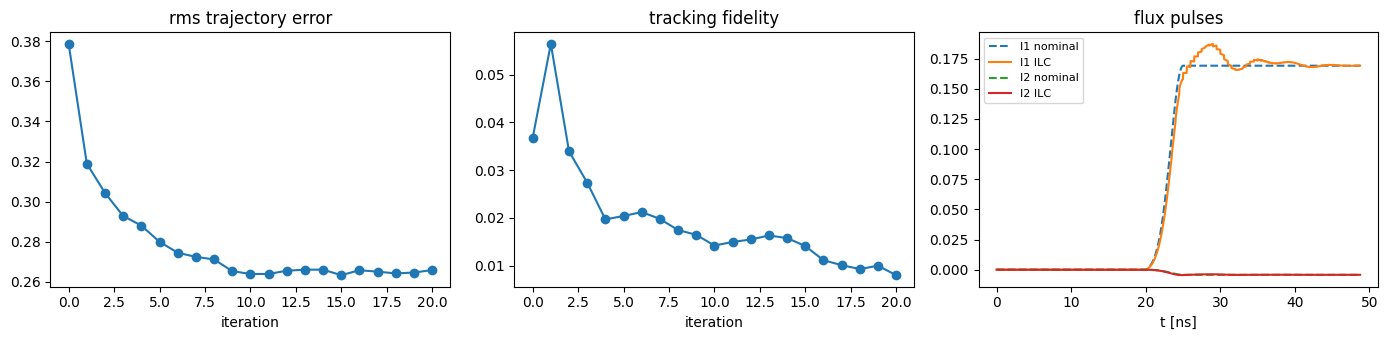

In [7]:
rng = np.random.default_rng(0)
N_ITER, GAIN, SUBSTEPS = 20, 0.7, 4
_, U_ref = ilc.simulate_rollout(ctrl)                             # nominal map to track

c_k, history = ctrl, []
for it in range(N_ITER + 1):
    y_true, U_hw = ilc.simulate_rollout(c_k, model=real_model, substeps=SUBSTEPS)   # noise-free, for scoring only
    history.append((np.sqrt(np.mean((y_true - y_nom) ** 2)), tracking_fidelity(model, U_hw, U_ref)))
    print(f"iter {it}: rms trajectory error {history[-1][0]:.4f}   tracking fidelity {history[-1][1]:.5f}")
    if it == N_ITER:
        break
    # "hardware" measurement: 4 times only, with shot noise
    y_meas, _ = ilc.simulate_rollout(c_k, model=real_model, substeps=SUBSTEPS,
                                     shots=SHOTS, rng=rng, times=meas_pos)
    c_k, e_filt, coeffs = ilc.update_pulse(c_k, y_meas, y_nom, V_r, U_r, Sigma_r,
                                           rows=meas_rows, gain=GAIN)

ctrl_ilc = c_k
h = np.array(history)
fig, ax = plt.subplots(1, 3, figsize=(14, 3.5))
ax[0].plot(h[:, 0], "o-"); ax[0].set_title("rms trajectory error"); ax[0].set_xlabel("iteration")
ax[1].plot(h[:, 1], "o-"); ax[1].set_title("tracking fidelity"); ax[1].set_xlabel("iteration")
for i, lab in enumerate(["I1", "I2"]):
    ax[2].plot(ctrl.t_mid, ctrl.I[i], "--", label=f"{lab} nominal")
    ax[2].plot(ctrl.t_mid, ctrl_ilc.I[i], label=f"{lab} ILC")
ax[2].set_title("flux pulses"); ax[2].set_xlabel("t [ns]"); ax[2].legend(fontsize=8)
plt.tight_layout()

## Adaptive SVD-ILC (Gauss-Newton parameter fit)
The correction uses all controls (flux and drives) on an equal footing; the SVD decides which directions to use. The fitted parameters are the list `FIT` you choose.
Each iteration:
1. **Measure** the hardware at the selected times (shot noise) and **fit** the mismatched parameters $\hat\theta$ by Gauss-Newton on all measurements so far: $\min_\theta \sum_j \|y_{\text{meas},j} - y(a_j;\theta)\|^2_W + \|(\theta-\theta_0)/\sigma_0\|^2$.
2. **Re-linearize**: control Jacobian and SVD of the *fitted* model at the current pulse, over all 6 controls jointly.
3. **Update** the controls toward the original nominal trajectory `y_nom`, using the fitted model's noise-free prediction as the error; the gain is halved until the model predicts an improvement. Re-pick the measurement times from the new error modes.

iter 0: rms err 0.3786  tracking F 0.03675  theta [0.05 0.05]
   fit chi2/meas 1.28 (grid scan)
   forgetting factor lambda = 0.000
iter 1: rms err 0.3663  tracking F 0.00371  theta [-0.4477  0.5427]
   fit chi2/meas 1.08 (grid scan)
   forgetting factor lambda = 0.000
iter 2: rms err 0.2751  tracking F 0.31762  theta [0.5492 0.54  ]
   fit chi2/meas 1.12
   forgetting factor lambda = 0.000
iter 3: rms err 0.2315  tracking F 0.12597  theta [0.5494 0.5479]
   fit chi2/meas 1.10
   forgetting factor lambda = 0.887
iter 4: rms err 0.1065  tracking F 0.14351  theta [0.5495 0.5482]
   fit chi2/meas 1.07
   forgetting factor lambda = 0.008
iter 5: rms err 0.2789  tracking F 0.34542  theta [0.5495 0.5504]
   fit chi2/meas 1.08
   forgetting factor lambda = 0.546
iter 6: rms err 0.1329  tracking F 0.33631  theta [0.5495 0.5496]
   fit chi2/meas 1.05
   forgetting factor lambda = 0.842
iter 7: rms err 0.0763  tracking F 0.46413  theta [0.5494 0.5492]
   fit chi2/meas 1.05
   forgetting factor l

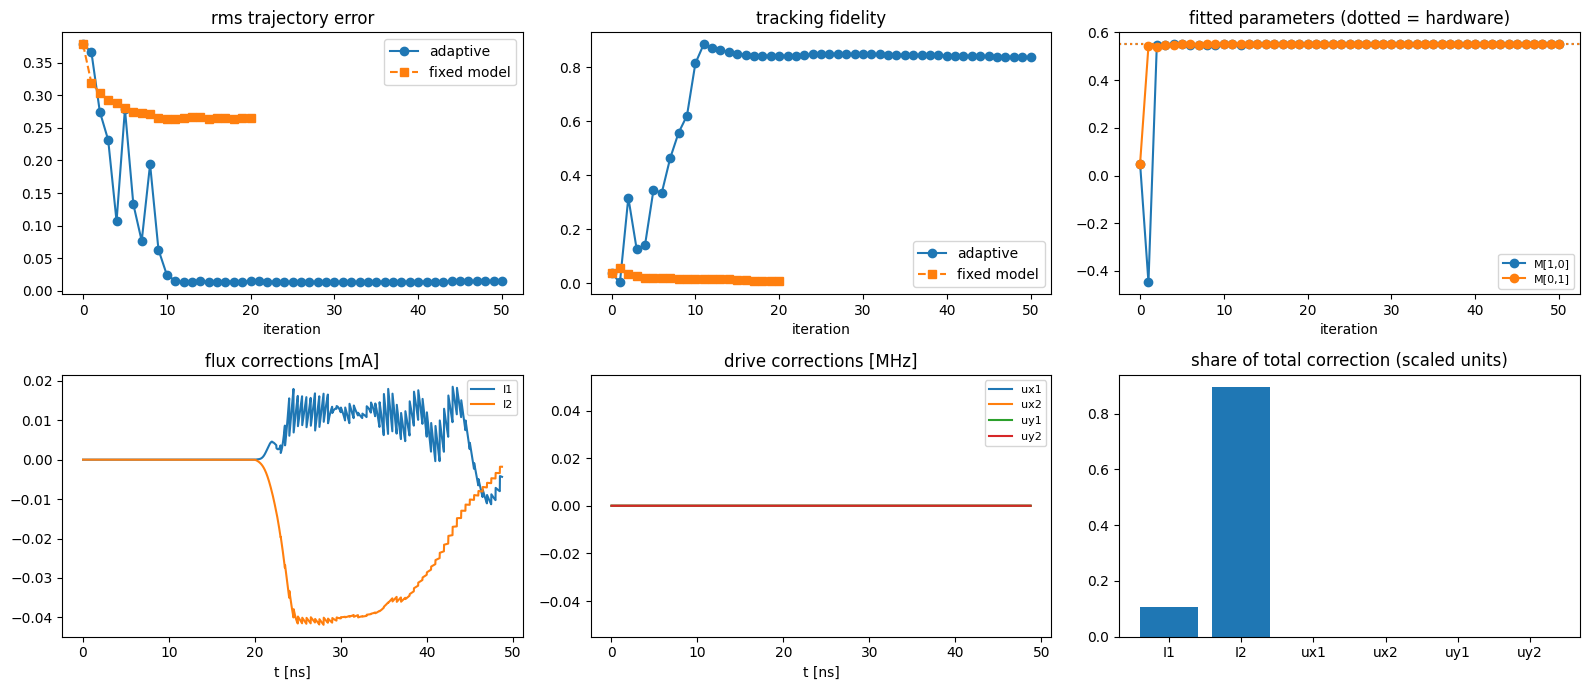

In [14]:
from ilc import get_param, run_adaptive_ilc

SVD_RANK = 20                    # modes per re-linearization (one SVD over all 6 controls)
N_TIMES = SVD_RANK                # measurement times per iteration
N_ITER_A = 50

USE_DRIVES = False                                                 # False: ILC corrects flux (I1, I2) only
ACTIVE = CHANNELS if USE_DRIVES else ["I1", "I2"]

# ---- model parameters to fit (you choose) ------------------------------------
# Available names: "M[i,j]" (i, j in 0/1), "J", "q1.f_max", "q2.f_max", "q1.alpha",
# "q2.alpha", "q1.asymmetry", "q2.asymmetry", "q1.flux_offset", "q2.flux_offset", "I_idle[i]"
FIT = ["M[1,0]", "M[0,1]"]
PRIOR_STD = [1.0] * len(FIT)      # Gaussian prior around the offline values (same units as each parameter)
SCAN = {n: (get_param(params, n) - 1.0, get_param(params, n) + 1.5) for n in FIT}
#   grid-scan ranges that seed Gauss-Newton (needed where dy/dtheta = 0 at the start);
#   set SCAN = None to skip, or give your own {name: (lo, hi)}

# Forgetting-factor ILC: a_{k+1} = a_0 + lambda (a_k - a_0) + delta_a,
# lambda = exp(-sum(((theta_k - theta_{k-1}) / FORGET_SIGMA)^2)). None = accumulate all corrections.
FORGET_SIGMA = [0.001] * len(FIT)   # same units as each FIT parameter

ilc_a = SVDILC(model, states, list(paulis.values()), checkpoints, active_channels=ACTIVE)
ctrl_adaptive, log_a = run_adaptive_ilc(
    ilc_a, ctrl, y_nom, params, real_model, FIT, scan=SCAN, prior_std=PRIOR_STD,
    n_iter=N_ITER_A, r_rank=SVD_RANK, n_times=N_TIMES, shots=SHOTS, substeps=SUBSTEPS,
    U_ref=U_ref, forget_sigma=FORGET_SIGMA, required_times=REQUIRED)

th = np.array(log_a["theta"])
fig, ax = plt.subplots(2, 3, figsize=(16, 7))
ax[0, 0].plot(log_a["rms"], "o-", label="adaptive"); ax[0, 0].plot(h[:, 0], "s--", label="fixed model")
ax[0, 0].set_title("rms trajectory error"); ax[0, 0].set_xlabel("iteration"); ax[0, 0].legend()
ax[0, 1].plot(log_a["tracking_F"], "o-", label="adaptive"); ax[0, 1].plot(h[:, 1], "s--", label="fixed model")
ax[0, 1].set_title("tracking fidelity"); ax[0, 1].set_xlabel("iteration"); ax[0, 1].legend()
for i, n in enumerate(FIT):
    ax[0, 2].plot(th[:, i], "o-", color=f"C{i}", label=n)
    ax[0, 2].axhline(get_param(real_params, n), ls=":", color=f"C{i}")
ax[0, 2].set_title("fitted parameters (dotted = hardware)"); ax[0, 2].set_xlabel("iteration"); ax[0, 2].legend(fontsize=8)
# correction applied on every control channel
da = np.vstack([ctrl_adaptive.I - ctrl.I, ctrl_adaptive.ux - ctrl.ux, ctrl_adaptive.uy - ctrl.uy])
for k, (name, a) in enumerate(zip(["I1", "I2", "ux1", "ux2", "uy1", "uy2"], da)):
    ax[1, 0 if k < 2 else 1].plot(ctrl.t_mid, a * (1 if k < 2 else 1e3), label=name)
ax[1, 0].set_title("flux corrections [mA]"); ax[1, 1].set_title("drive corrections [MHz]")
for a in ax[1, :2]: a.set_xlabel("t [ns]"); a.legend(fontsize=8)
share = (da / ilc_a.scales[:, None]) ** 2
ax[1, 2].bar(["I1", "I2", "ux1", "ux2", "uy1", "uy2"], share.sum(axis=1) / share.sum())
ax[1, 2].set_title("share of total correction (scaled units)")
plt.tight_layout()

### Comparison: offline analytical crosstalk inverse
With the new mutual-inductance matrix $\hat M$, the analytical fix replays the nominal flux on every SQUID:
$I_{\text{fix}}(t) = \hat M^{-1} M_{\text{offline}}\, I_{\text{nom}}(t)$ (drives unchanged). Computed with the fitted $\hat M$ (from the adaptive ILC) and with the true hardware $M$, and scored on the hardware model (noise-free) against the ILC pulses.

M offline:
 [[2.   0.05]
 [0.05 2.  ]] 
M fitted:
 [[2.     0.5499]
 [0.5495 2.    ]] 
M hardware:
 [[2.   0.55]
 [0.55 2.  ]]

pulse                      rms traj err  tracking F
nominal pulse                    0.3786     0.03675
fixed-model SVD-ILC              0.2659     0.00800
adaptive SVD-ILC                 0.0142     0.83816
analytic (fitted M)              0.0002     1.00000
analytic (true M)                0.0000     1.00000


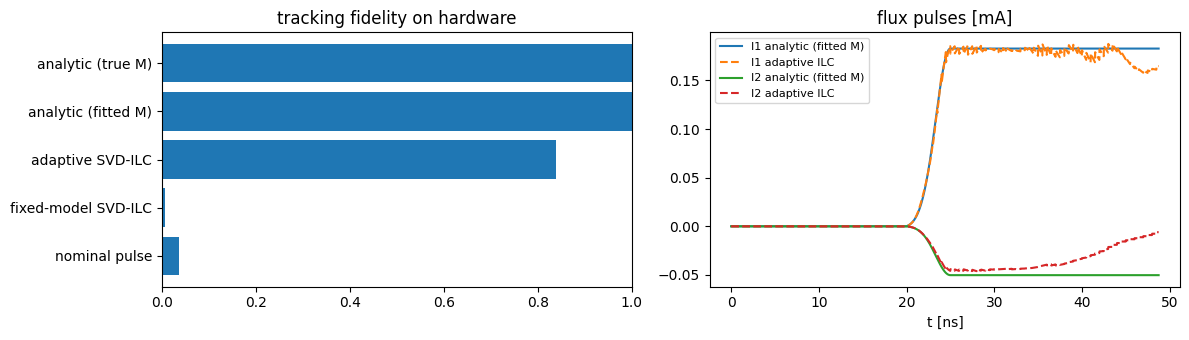

In [15]:
from ilc import with_parameters

def crosstalk_inverse(ctrl_nom, M_offline, M_new):
    # same flux on each SQUID as the offline design: M_new @ I_fix = M_offline @ I_nom
    I_fix = np.linalg.solve(M_new, M_offline @ ctrl_nom.I)
    return Controls(ctrl_nom.dt, I_fix, ctrl_nom.ux.copy(), ctrl_nom.uy.copy())

M_fit = with_parameters(params, FIT, log_a["theta"][-1]).p.M      # final fitted matrix
print("M offline:\n", params.M, "\nM fitted:\n", np.round(M_fit, 4), "\nM hardware:\n", real_params.M)

candidates = {
    "nominal pulse":            ctrl,
    "fixed-model SVD-ILC":      ctrl_ilc,
    "adaptive SVD-ILC":         ctrl_adaptive,
    "analytic (fitted M)":      crosstalk_inverse(ctrl, params.M, M_fit),
    "analytic (true M)":        crosstalk_inverse(ctrl, params.M, real_params.M),
}
rows = []
for name, c in candidates.items():
    y_hw, U_hw = ilc.simulate_rollout(c, model=real_model, substeps=SUBSTEPS)
    rows.append((name, np.sqrt(np.mean((y_hw - y_nom) ** 2)), tracking_fidelity(model, U_hw, U_ref)))

print(f"\n{'pulse':26s} {'rms traj err':>12s} {'tracking F':>11s}")
for name, rms, F in rows:
    print(f"{name:26s} {rms:12.4f} {F:11.5f}")

fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
names = [r[0] for r in rows]
ax[0].barh(names, [r[2] for r in rows]); ax[0].set_xlim(0, 1); ax[0].set_title("tracking fidelity on hardware")
for i, lab in enumerate(["I1", "I2"]):
    ax[1].plot(ctrl.t_mid, candidates["analytic (fitted M)"].I[i], label=f"{lab} analytic (fitted M)")
    ax[1].plot(ctrl.t_mid, ctrl_adaptive.I[i], "--", label=f"{lab} adaptive ILC")
ax[1].set_title("flux pulses [mA]"); ax[1].set_xlabel("t [ns]"); ax[1].legend(fontsize=8)
plt.tight_layout()

### Populations under the optimized SVD-ILC pulse
Computational-state and leakage populations vs time (QuTiP ODE solver), starting from `PSI0_LABELS`:
the nominal pulse in the offline model (target), the nominal pulse on the hardware, and the adaptive SVD-ILC pulse on the hardware.

target: nominal pulse, offline model     final: 00 0.0127  01 0.9848  10 0.0025  11 0.0000  leak 0.0001
nominal pulse, hardware                  final: 00 0.0127  01 0.0543  10 0.9329  11 0.0000  leak 0.0001
adaptive SVD-ILC pulse, hardware         final: 00 0.0127  01 0.9680  10 0.0192  11 0.0000  leak 0.0001


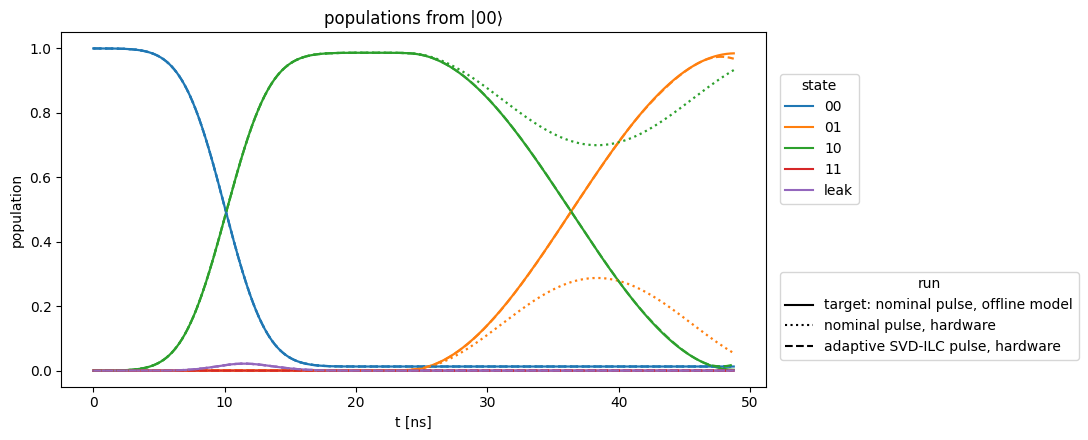

In [16]:
PSI0_LABELS = ("0", "0")                      # initial product state, e.g. ("+", "+")
psi0 = product_state(model, *PSI0_LABELS)

pop_labels = ["00", "01", "10", "11", "leak"]
def pop_ops(m):
    P = [m.basis(0, 0).proj(), m.basis(0, 1).proj(), m.basis(1, 0).proj(), m.basis(1, 1).proj()]
    return P + [qt.qeye(m.dims) - sum(P)]

runs = [("target: nominal pulse, offline model", model, ctrl, "-"),
        ("nominal pulse, hardware", real_model, ctrl, ":"),
        ("adaptive SVD-ILC pulse, hardware", real_model, ctrl_adaptive, "--")]

fig, ax = plt.subplots(figsize=(11, 4.5))
for title, m, c, ls in runs:
    r = m.evolve(c, psi0, e_ops=pop_ops(m))
    for k, (lab, pop) in enumerate(zip(pop_labels, r.expect)):
        ax.plot(r.times, pop, ls=ls, color=f"C{k}", lw=1.6)
    print(f"{title:40s} final: " + "  ".join(f"{l} {p[-1]:.4f}" for l, p in zip(pop_labels, r.expect)))

# two legends: colour = state, line style = run
from matplotlib.lines import Line2D
state_leg = ax.legend([Line2D([], [], color=f"C{k}") for k in range(len(pop_labels))], pop_labels,
                      title="state", loc="center left", bbox_to_anchor=(1.01, 0.7))
ax.add_artist(state_leg)
ax.legend([Line2D([], [], color="k", ls=ls) for _, _, _, ls in runs], [t for t, *_ in runs],
          title="run", loc="center left", bbox_to_anchor=(1.01, 0.2))
ax.set_xlabel("t [ns]"); ax.set_ylabel("population")
ax.set_title(f"populations from |{''.join(PSI0_LABELS)}⟩")
plt.tight_layout()

## GRAPE hooks
* `model.slice_hamiltonians(ctrl)`: dense $H_k$ per slice, shape `(N, D, D)`
* `model.slice_propagators(ctrl)`: $U_k = e^{-iH_k\,dt}$
* `model.propagator(ctrl, "pwc" | "ode")`: total unitary
* `model.control_operators()`: $\partial H/\partial u$ for the z, x, y controls
* `model.detuning_jacobian(I)`: $\partial\Delta_i/\partial I_j$, the chain rule for optimizing in current space (it is zero at a sweet spot)
* `model.gate_fidelity(U, target)`: leakage-aware average gate fidelity on the computational subspace

The pack/unpack helpers below give a flat parameter vector for an external optimizer.

In [11]:
def pack(ctrl: Controls) -> np.ndarray:
    return np.concatenate([ctrl.I.ravel(), ctrl.ux.ravel(), ctrl.uy.ravel()])

def unpack(x: np.ndarray, n_slices: int, dt: float) -> Controls:
    I, ux, uy = np.split(np.asarray(x), 3)
    return Controls(dt, I.reshape(2, n_slices), ux.reshape(2, n_slices), uy.reshape(2, n_slices))

def infidelity(x, target, n_slices, dt):
    return 1 - model.gate_fidelity(model.propagator(unpack(x, n_slices, dt)), target)

# Example: score just the pi-pulse segment against X on qubit 1
X1 = qt.tensor(qt.sigmax(), qt.qeye(2)).full()
x_pi = pack(Controls(dt, ctrl.I[:, :N_pi], ctrl.ux[:, :N_pi], ctrl.uy[:, :N_pi]))
print("infidelity (pi pulse vs X1):", infidelity(x_pi, X1, N_pi, dt))

# Full sequence: magnitude of the computational-subspace block
U = model.propagator(ctrl, "pwc")
print("|U_sub| (rows/cols 00, 01, 10, 11):\n", np.round(np.abs(model.project_computational(U)), 3))

infidelity (pi pulse vs X1): 0.013113783030590853
|U_sub| (rows/cols 00, 01, 10, 11):
 [[0.113 0.025 0.993 0.   ]
 [0.992 0.003 0.113 0.05 ]
 [0.05  0.096 0.004 0.991]
 [0.001 0.982 0.024 0.085]]
